# Imitation: behaviour cloning, DAgger, MaxEnt IRL and GAIL on one racetrack

**Code:** [`algos/bc.py`](../algos/bc.py) · [`algos/dagger.py`](../algos/dagger.py) · [`algos/max_ent_irl.py`](../algos/max_ent_irl.py) · [`algos/gail.py`](../algos/gail.py) · [`experiments/bc_vs_dagger.py`](../experiments/bc_vs_dagger.py)
**Papers:** Pomerleau 1991 ([PDF](../papers/imitation-offline/pomerleau-1991-alvinn.pdf)), Ross et al. 2011 ([PDF](../papers/imitation-offline/ross-2011-dagger.pdf)), Ziebart et al. 2008 ([PDF](../papers/imitation-offline/ziebart-2008-maxent-irl.pdf)), Ho & Ermon 2016 ([PDF](../papers/imitation-offline/ho-ermon-2016-gail.pdf)) ·
**Notes:** [`papers/imitation-offline/notes.md`](../papers/imitation-offline/notes.md)

Four ways to learn from an expert, all on the same 7,126-state racetrack, all scored by **exact** expected return.
They differ in what they are allowed to see, and that is the whole story. Section 1 draws it.

What you will see:

1. Behaviour cloning on one seed can look almost perfect. Over five seeds its median stops improving, and covariate shift says why.
2. DAgger reaching the expert on a matched budget of expert labels.
3. MaxEnt IRL recovering a reward from a few demonstrations, where BC with the same data is still guessing.
4. GAIL: the *sign* of its manufactured reward decides whether the agent ever finishes, and more data can make it worse.

A self-contained Kaggle version of sections 2–3 is [`kaggle_01_behaviour_cloning_fails.ipynb`](kaggle_01_behaviour_cloning_fails.ipynb).
Runs on CPU. Run from the repo root or with the repo installed (`pip install -e .`).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from algos import bc, dagger, gail, max_ent_irl
from diagnostics.plots import racetrack_figure
from envs import solvers
from envs.racetrack import ACTION_NAMES, Racetrack

GAMMA = 0.99
plt.rcParams["figure.dpi"] = 110
env = Racetrack()                     # on_crash="stop": a crash strands the car, it is not teleported back
expert = env.optimal_policy(GAMMA)    # exact optimal policy, from value iteration on env.P
optimal = env.optimal_return(GAMMA)

## 0. The problem and the data

**Racetrack** (Sutton & Barto, exercise 5.12). A car starts on the start line `S` and must cross the finish line `F`.
Each step it chooses an acceleration in each direction, from $\{-1, 0, +1\}^2$: 9 actions.
Every step costs $-1$, so the objective is to finish fast. With probability 0.1 the acceleration fails.
A crash leaves the car stopped where it hit, and it must drive out (`on_crash="stop"`).

The **state** is (row, column, vertical speed, horizontal speed), flattened to one integer.
The **data** every method gets is a set of expert demonstrations: (state, action) pairs.

| column | meaning |
| --- | --- |
| `state` | integer index, decoded by `env.decode(state)` |
| `row`, `col` | the car's cell |
| `v_up`, `v_right` | speeds, 0 to 4 |
| `action` | index into 9 accelerations, `ACTION_NAMES[action]` |

7,126 states, 9 actions, exact optimal return -6.537

 state  row  col  v_up  v_right  action  name
  6750   14    4     0        0       6  dv=+1,dh=-1
  6280   13    4     1        0       8  dv=+1,dh=+1
  5361   11    5     2        1       8  dv=+1,dh=+1
  3992    8    7     3        2       5  dv=+0,dh=+1
  2643    5   10     3        3       2  dv=-1,dh=+1
  1789    3   14     2        4       1  dv=-1,dh=+0
  6750   14    4     0        0       6  dv=+1,dh=-1
  6280   13    4     1        0       8  dv=+1,dh=+1
  5361   11    5     2        1       8  dv=+1,dh=+1
  3992    8    7     3        2       5  dv=+0,dh=+1
  2643    5   10     3        3       2  dv=-1,dh=+1
  1789    3   14     2        4       1  dv=-1,dh=+0


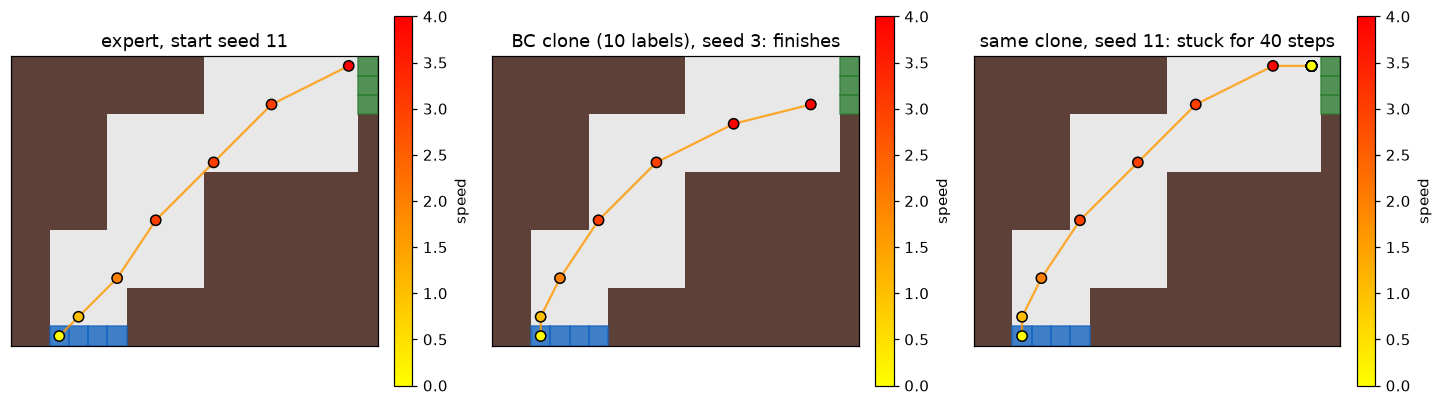

10-label clone finishes within 40 steps on 17 of 20 start seeds


In [2]:
print(f"{env.n_states:,} states, {env.n_actions} actions, exact optimal return {optimal:.3f}\n")

states, actions = bc.collect_demonstrations(env, expert, n_labels=12, seed=1)
print(f"{'state':>6} {'row':>4} {'col':>4} {'v_up':>5} {'v_right':>8} {'action':>7}  name")
for s, a in zip(states, actions):
    (row, col), vu, vr = env.decode(int(s))
    print(f"{s:>6} {row:>4} {col:>4} {vu:>5} {vr:>8} {a:>7}  {ACTION_NAMES[a]}")

def one_episode(policy_fn, seed):
    env.reset(seed=seed); visited = [env.state]
    for _ in range(40):
        _, _, terminated, truncated, _ = env.step(policy_fn(env.state)); visited.append(env.state)
        if terminated or truncated: break
    return visited

clone_states, clone_actions = bc.collect_demonstrations(env, expert, n_labels=10, seed=1)
clone = bc.fit(env, clone_states, clone_actions)
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2))
racetrack_figure(env, axs[0], states=one_episode(lambda s: int(expert[s]), seed=11), title="expert, start seed 11")
racetrack_figure(env, axs[1], states=one_episode(clone, seed=3), title="BC clone (10 labels), seed 3: finishes")
racetrack_figure(env, axs[2], states=one_episode(clone, seed=11), title="same clone, seed 11: stuck for 40 steps")
plt.show()

finished = [one_episode(clone, seed)[-1] == env.finished_state for seed in range(20)]
print(f"10-label clone finishes within 40 steps on {sum(finished)} of 20 start seeds")

Blue cells are the start line, green the finish, brown is off-track. Dot colour is speed.
The clone copies the expert well on states it has seen. On seed 11 it crashes into the wall one cell short of the finish and stops at speed 0. No demonstration was ever stopped there, its nearest-neighbour guess is wrong, and it stays stuck.
That is covariate shift in one picture; section 2 measures it.

## 1. What each method is allowed to see

This table is the reason the four methods give different answers on the same data.
Read each result below against its row.

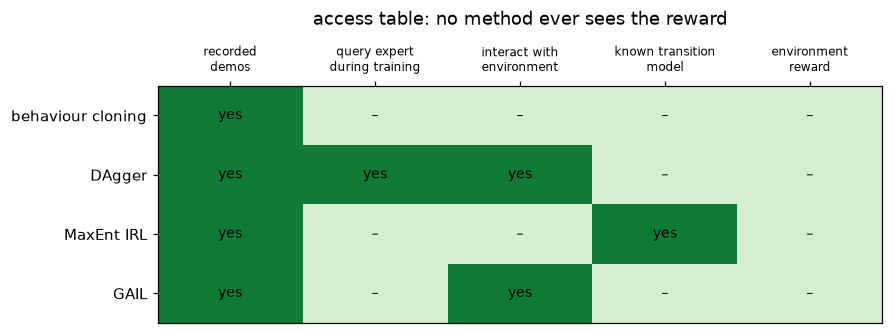

In [3]:
methods = ["behaviour cloning", "DAgger", "MaxEnt IRL", "GAIL"]
columns = ["recorded\ndemos", "query expert\nduring training", "interact with\nenvironment", "known transition\nmodel", "environment\nreward"]
access = np.array([[1, 0, 0, 0, 0],
                   [1, 1, 1, 0, 0],
                   [1, 0, 0, 1, 0],
                   [1, 0, 1, 0, 0]])
fig, ax = plt.subplots(figsize=(8.5, 2.8))
ax.imshow(access, cmap="Greens", vmin=-0.3, vmax=1.3, aspect="auto")
ax.set_xticks(range(len(columns)), columns, fontsize=8); ax.set_yticks(range(len(methods)), methods)
for i in range(len(methods)):
    for j in range(len(columns)):
        ax.text(j, i, "yes" if access[i, j] else "–", ha="center", va="center", fontsize=9)
ax.xaxis.tick_top(); ax.set_title("access table: no method ever sees the reward", pad=40); plt.show()

## 2. Behaviour cloning, one seed: watch the covariate shift

BC is supervised learning on (state, expert action) pairs. The classifier here is nearest-neighbour ([`algos/bc.py:58-81`](../algos/bc.py)).
It has no training loop, so a failure cannot be blamed on the optimiser. It can only be the data.

**Covariate shift** ([`algos/bc.py:99-112`](../algos/bc.py)) is the mean distance from a state the clone visits to the nearest demonstrated state.
Near zero: the clone stays where the expert was. Large: the clone has left the expert's world, and more expert data lands where it already has data.

This is **one seed**. Read the return column against section 3, which runs five.

 labels  coverage  covariate shift  exact return  gap to expert
     10     0.002            0.879        -22.84         -16.30
     20     0.004            0.802        -16.15          -9.62
     40     0.005            0.687        -28.11         -21.57
     80     0.008            0.426        -24.36         -17.82
    160     0.015            0.016         -6.87          -0.34
    320     0.017            0.007         -6.88          -0.34
    640     0.020            0.004         -6.86          -0.32


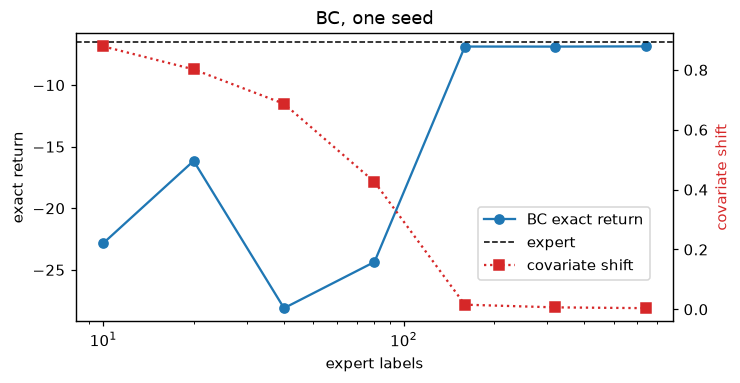

In [4]:
LABELS = (10, 20, 40, 80, 160, 320, 640)
rows = []
for n in LABELS:
    s, a = bc.collect_demonstrations(env, expert, n, seed=1)
    policy = bc.fit(env, s, a)
    visited = bc.rollout(env, policy, n_episodes=50, seed=90_000)
    rows.append((n, env.demonstration_coverage(s), bc.covariate_shift(env, s, visited), bc.exact_return(env, policy, GAMMA)))

print(f"{'labels':>7} {'coverage':>9} {'covariate shift':>16} {'exact return':>13} {'gap to expert':>14}")
for n, cov, shift, value in rows:
    print(f"{n:>7} {cov:>9.3f} {shift:>16.3f} {value:>13.2f} {value - optimal:>14.2f}")

fig, ax1 = plt.subplots(figsize=(7, 3.4))
ax1.plot(LABELS, [r[3] for r in rows], "o-", label="BC exact return")
ax1.axhline(optimal, color="k", ls="--", lw=1, label="expert")
ax1.set_xscale("log"); ax1.set_xlabel("expert labels"); ax1.set_ylabel("exact return")
ax2 = ax1.twinx(); ax2.plot(LABELS, [r[2] for r in rows], "s:", color="tab:red", label="covariate shift")
ax2.set_ylabel("covariate shift", color="tab:red")
fig.legend(loc="lower right", bbox_to_anchor=(0.88, 0.2)); plt.title("BC, one seed"); plt.show()

On this seed the return jumps once the covariate shift falls near zero: the clone has enough labels that it no longer leaves the expert's states.
Whether that happens at a given budget depends on which demonstrations were drawn. Section 3 shows how often it does.

## 3. DAgger on the same budget of expert labels

DAgger lets the learner drive and asks the expert to label the states the **learner** reaches ([`algos/dagger.py:65-126`](../algos/dagger.py)).
`beta` is the chance of following the expert while collecting. It starts at 1 and decays by 0.6 each round (lines 92, 97, 101-103).

The fair comparison counts **expert labels**, not "demonstrations" against "rounds". Five seeds, median and range.

(45 s)

 labels         BC median [min, max]     DAgger median [min, max]
     10    -53.17 [ -75.74,  -22.84]    -32.21 [ -49.55,  -10.55]
     20    -16.15 [ -52.53,   -7.37]    -10.48 [ -17.08,   -8.34]
     40    -19.41 [ -40.79,  -17.65]     -9.02 [ -17.73,   -6.79]
     80    -17.39 [ -24.36,  -14.36]     -6.81 [  -7.58,   -6.73]
    160    -12.93 [ -20.03,   -6.87]     -6.77 [  -7.51,   -6.67]
    320    -12.93 [ -14.82,   -6.88]     -6.64 [  -8.00,   -6.63]


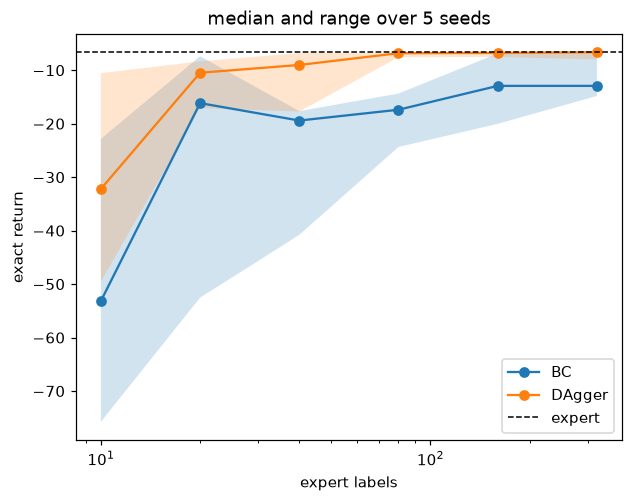

In [5]:
BUDGETS, SEEDS = (10, 20, 40, 80, 160, 320), range(1, 6)
t0 = time.time()
bc_vals = np.zeros((len(BUDGETS), len(SEEDS))); dg_vals = np.zeros_like(bc_vals)
for i, budget in enumerate(BUDGETS):
    for j, seed in enumerate(SEEDS):
        s, a = bc.collect_demonstrations(env, expert, budget, seed=seed)
        bc_vals[i, j] = bc.exact_return(env, bc.fit(env, s, a), GAMMA)
        dg_vals[i, j] = dagger.exact_return(env, dagger.train(env, expert, budget, seed=seed), GAMMA)
print(f"({time.time() - t0:.0f} s)\n")

print(f"{'labels':>7} {'BC median [min, max]':>28} {'DAgger median [min, max]':>28}")
for i, budget in enumerate(BUDGETS):
    b, d = bc_vals[i], dg_vals[i]
    print(f"{budget:>7} {f'{np.median(b):8.2f} [{b.min():7.2f}, {b.max():7.2f}]':>28} "
          f"{f'{np.median(d):8.2f} [{d.min():7.2f}, {d.max():7.2f}]':>28}")

for vals, name in ((bc_vals, "BC"), (dg_vals, "DAgger")):
    plt.plot(BUDGETS, np.median(vals, 1), "o-", label=name)
    plt.fill_between(BUDGETS, vals.min(1), vals.max(1), alpha=0.2)
plt.axhline(optimal, color="k", ls="--", lw=1, label="expert")
plt.xscale("log"); plt.xlabel("expert labels"); plt.ylabel("exact return")
plt.title("median and range over 5 seeds"); plt.legend(); plt.show()

What the table does not show: DAgger needs the expert **available during training**.
With a scripted controller that is free. With a human it is the reason DAgger is common in papers and rare in products.

## 4. MaxEnt IRL: recover the reward, then plan

IRL asks what reward would make the demonstrations optimal ([`algos/max_ent_irl.py:173-189`](../algos/max_ent_irl.py)). The loop:

1. guess a reward $r = \phi\,\theta$ (here one feature per track cell: 118 parameters, not 7,126)
2. soft value iteration: `logsumexp` where value iteration has `max` (lines 69-85)
3. expected state visitation of that soft-optimal policy (lines 88-98)
4. gradient = expert visitation − learner visitation (line 184)

It needs the **transition model**, which no other method here uses.
The demonstrator is "noisily rational": the optimal action 60% of the time, uniform otherwise.
BC and IRL see exactly the same demonstrations.

reward features: 118   gamma: 0.95


exact optimum -5.826   demonstrator -8.317



(44 s)

 demos         BC   IRL, then plan
    10    -13.516           -5.869
    30     -9.410           -5.833
   100     -5.963           -5.831
   300     -5.844           -5.827


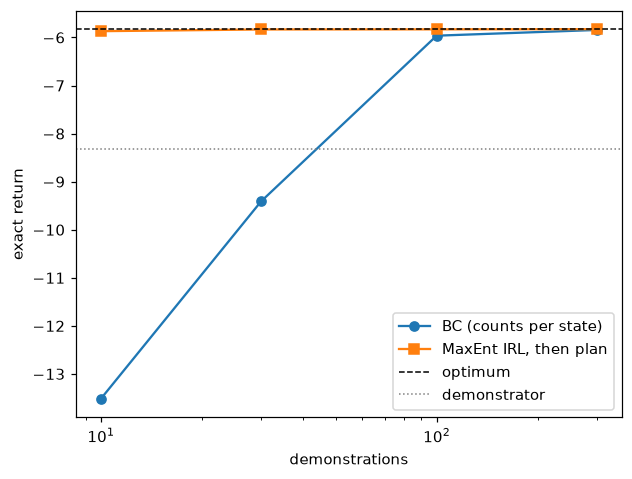

In [6]:
model = solvers.flatten(env.P, env.n_states, env.n_actions)
features = max_ent_irl.racetrack_features(env)
noisy_expert = max_ent_irl.noisily_rational_expert(env, max_ent_irl.GAMMA)
irl_gamma = max_ent_irl.GAMMA
print(f"reward features: {features.shape[1]}   gamma: {irl_gamma}")
print(f"exact optimum {env.optimal_return(irl_gamma):+.3f}   demonstrator {env.policy_return(noisy_expert, irl_gamma):+.3f}\n")

t0 = time.time()
DEMOS = (10, 30, 100, 300)
irl_rows = []
for n in DEMOS:
    demos = max_ent_irl.collect_demonstrations(env, noisy_expert, n, seed=0)
    clone = max_ent_irl.behaviour_clone(env.n_states, env.n_actions, demos)
    reward, _ = max_ent_irl.train(env, demos, features)
    irl_rows.append((n, env.policy_return(clone, irl_gamma), env.policy_return(max_ent_irl.plan(model, reward), irl_gamma)))
print(f"({time.time() - t0:.0f} s)\n")

print(f"{'demos':>6} {'BC':>10} {'IRL, then plan':>16}")
for n, b, i in irl_rows:
    print(f"{n:>6} {b:>10.3f} {i:>16.3f}")
plt.plot(DEMOS, [r[1] for r in irl_rows], "o-", label="BC (counts per state)")
plt.plot(DEMOS, [r[2] for r in irl_rows], "s-", label="MaxEnt IRL, then plan")
plt.axhline(env.optimal_return(irl_gamma), color="k", ls="--", lw=1, label="optimum")
plt.axhline(env.policy_return(noisy_expert, irl_gamma), color="grey", ls=":", lw=1, label="demonstrator")
plt.xscale("log"); plt.xlabel("demonstrations"); plt.ylabel("exact return"); plt.legend(); plt.show()

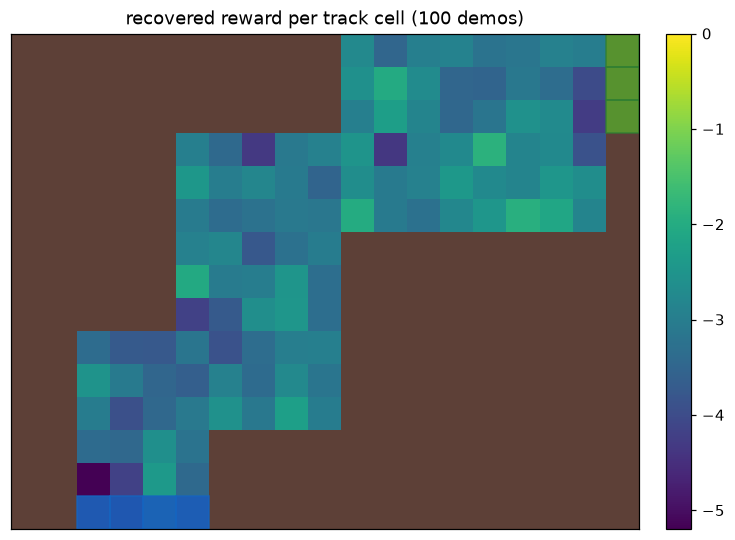

In [7]:
reward, _ = max_ent_irl.train(env, max_ent_irl.collect_demonstrations(env, noisy_expert, 100, seed=0), features)
racetrack_figure(env, states=None, cell_values=env.cell_values(reward), title="recovered reward per track cell (100 demos)")
plt.show()

BC here has one free choice per state, 7,126 of them, so most of its policy is a coin flip until it has seen a lot of data.
IRL fits 118 numbers and uses the transition model to spread each observation over every state that leads to it.
The advantage comes from a large state space, not from imitation as such. The file's docstring records the reverse result on a 7x7 grid.

## 5. GAIL: imitation by interaction, with a reward it makes up

GAIL trains a discriminator $D(s,a)$ to tell expert pairs from learner pairs, then runs Q-learning on a reward built from $D$ ([`algos/gail.py:131-191`](../algos/gail.py)).
It may interact with the environment. It never sees the environment's reward, and it cannot query the expert.

The algebraic form of that reward is a choice ([`algos/gail.py:106-128`](../algos/gail.py)):

| form | reward | range |
| --- | --- | --- |
| positive | $-\log(1 - D)$ | $(0, \infty)$: every step pays |
| negative | $\log D$ | $(-\infty, 0)$: every step costs |
| symmetric | $\log D - \log(1 - D)$ | crosses 0 at $D = 0.5$ |

In [8]:
gail_expert = gail.noisily_rational_expert(env)
demo_s, demo_a = gail.collect_demonstrations(env, gail_expert, 30, seed=0)
print(f"demonstrator {env.policy_return(gail_expert, GAMMA):.2f}   optimum {optimal:.2f}   {len(demo_s):,} expert pairs\n")

t0 = time.time()
print(f"{'reward form':>12} {'exact return, seeds 0 / 1 / 2':>34}")
for form in gail.REWARD_FORMS:
    vals = [env.policy_return(gail.train(env, demo_s, demo_a, seed=seed, reward_form=form)[0].argmax(1), GAMMA)
            for seed in (0, 1, 2)]
    print(f"{form:>12} " + " ".join(f"{v:>10.2f}" for v in vals))
print(f"\n({time.time() - t0:.0f} s)")

demonstrator -9.01   optimum -6.54   290 expert pairs

 reward form      exact return, seeds 0 / 1 / 2


    positive    -100.00    -100.00    -100.00


    negative     -11.37     -12.94     -18.83


   symmetric     -99.56     -99.77     -98.41

(13 s)


A return of −100 means the car never finishes: the exact evaluation has no time limit, and $-1/(1-\gamma) = -100$ at $\gamma = 0.99$.
Under the positive form every step earns something, so never finishing is optimal. That is arithmetic, not a tuning failure.
The negative form wins here because "every step costs" happens to be the right prior for a race. It would be wrong on a task where the goal is to survive.

(28 s)

 demos       BC median [min, max]     GAIL median [min, max]
     3   -68.78 [ -77.97, -46.55]   -11.92 [ -16.71,  -9.81]
    10   -68.51 [ -71.12, -20.40]   -17.26 [ -32.18, -14.08]
    30    -9.01 [ -15.65,  -8.79]   -11.37 [ -12.25,  -9.20]
   100    -7.02 [  -8.97,  -6.66]   -27.03 [ -27.95, -11.88]


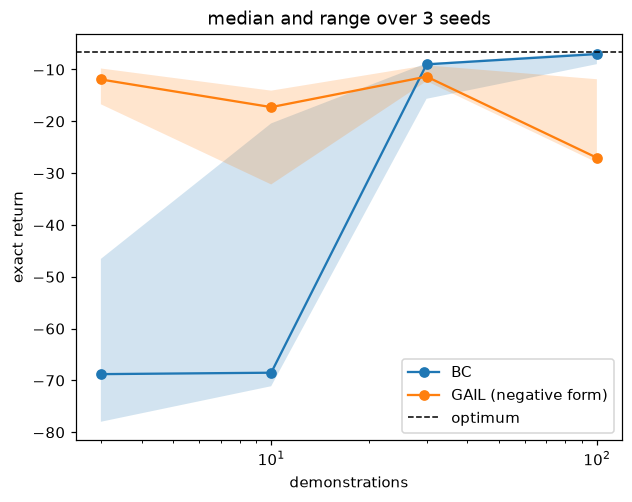

In [9]:
t0 = time.time()
GDEMOS = (3, 10, 30, 100)
bc_g, gail_g = np.zeros((len(GDEMOS), 3)), np.zeros((len(GDEMOS), 3))
for i, n in enumerate(GDEMOS):
    for seed in (0, 1, 2):
        s, a = gail.collect_demonstrations(env, gail_expert, n, seed=seed)
        bc_g[i, seed] = env.policy_return(gail.behaviour_clone(env.n_states, env.n_actions, s, a, seed=seed), GAMMA)
        gail_g[i, seed] = env.policy_return(gail.train(env, s, a, seed=seed, reward_form="negative")[0].argmax(1), GAMMA)
print(f"({time.time() - t0:.0f} s)\n")
print(f"{'demos':>6} {'BC median [min, max]':>26} {'GAIL median [min, max]':>26}")
for i, n in enumerate(GDEMOS):
    b, g = bc_g[i], gail_g[i]
    print(f"{n:>6} {f'{np.median(b):8.2f} [{b.min():7.2f},{b.max():7.2f}]':>26} {f'{np.median(g):8.2f} [{g.min():7.2f},{g.max():7.2f}]':>26}")
for vals, name in ((bc_g, "BC"), (gail_g, "GAIL (negative form)")):
    plt.plot(GDEMOS, np.median(vals, 1), "o-", label=name); plt.fill_between(GDEMOS, vals.min(1), vals.max(1), alpha=0.2)
plt.axhline(optimal, color="k", ls="--", lw=1, label="optimum")
plt.xscale("log"); plt.xlabel("demonstrations"); plt.ylabel("exact return"); plt.title("median and range over 3 seeds")
plt.legend(); plt.show()

Read the crossover. With very few demonstrations BC has almost nothing to copy and GAIL can go and look, so GAIL wins.
With more data BC catches up, and GAIL does not improve with more data the way a method short of data would.
GAIL's policy chases a reward that changes every round. A minimax game does not converge the way a minimisation does.

## 6. What breaks, and how you would know

| method | symptom | cause |
| --- | --- | --- |
| BC | perfect score you did not expect | the environment gives a free correction (`on_crash="restart"` teleports to the start line) or the horizon is too short for errors to compound |
| BC | covariate shift near 0, return still poor | the clone is on-distribution and wrong: a modelling problem; DAgger will not help |
| DAgger | worse than BC per label | `beta = 0` from round one; measured: 2,426 labels to match what the decayed schedule reaches in 80 |
| MaxEnt IRL | recovered reward makes the goal repulsive | demonstrations not padded to the horizon ([`max_ent_irl.py:116-148`](../algos/max_ent_irl.py)) |
| MaxEnt IRL | loses badly to BC | too few states: below a few hundred, counting actions per state wins |
| GAIL | behaves exactly like BC | discriminator has enough capacity to memorise pairs ([`gail.py:56-83`](../algos/gail.py)) |
| GAIL | survives but never finishes | positive reward form; see section 5 |

**Next:** [`offline_01_q_cql_bcq_iql.ipynb`](offline_01_q_cql_bcq_iql.ipynb): the same expert, now as a fixed log with rewards and no environment.